In [4]:
import pandas as pd
import numpy as np
df=pd.read_csv("/Bank_Churn.csv")
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.duplicated().any())


   CustomerId   Surname  CreditScore Geography  Gender  Age  Tenure  \
0    15634602  Hargrave          619    France  Female   42       2   
1    15647311      Hill          608     Spain  Female   41       1   
2    15619304      Onio          502    France  Female   42       8   
3    15701354      Boni          699    France  Female   39       1   
4    15737888  Mitchell          850     Spain  Female   43       2   

     Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  \
0       0.00              1          1               1        101348.88   
1   83807.86              1          0               1        112542.58   
2  159660.80              3          1               0        113931.57   
3       0.00              2          0               0         93826.63   
4  125510.82              1          1               1         79084.10   

   Exited  
0       1  
1       0  
2       1  
3       0  
4       0  
(10000, 13)
<class 'pandas.core.frame.DataFrame'>


1.***EDA***:
imported CSV files,
examined the size and data types in the table,
checked for missing values,
checked for duplicate rows

2. Let's look at the clients who left the bank and what attributes are most common among them. Let's test the hypothesis based on age, account activity, balance and product. Obviously we will group by the Exited column

In [28]:
median_age=df.loc[df["Exited"]==1,"Age"].median()
mean_age=df.loc[df["Exited"]==1,"Age"].mean()
print(mean_age)
print(median_age)

44.8379970544919
45.0


Here we can see the average age of a departing client, and conclude that these are mostly not young people

In [6]:
churned=df[df["Exited"]==1]
active_churn=(churned.groupby("IsActiveMember")).agg(clients_count=("CustomerId","count")),
avg_age=("Age","mean")
print(active_churn)

(                clients_count
IsActiveMember               
0                        1302
1                         735,)


here we can see that there were people with active accounts who left the bank, let's check them by the attributes age, balance and number of products

In [40]:
active_churn_details = (
    churned.groupby("IsActiveMember")
    .agg(
        clients_count=("CustomerId", "count"),
        avg_age=("Age", "mean"),
        median_balance=("Balance", "median"),
        avg_products=("NumOfProducts", "mean"),
    )
    .round(2)
    .reset_index()
)

print(active_churn_details)


   IsActiveMember  clients_count  avg_age  median_balance  avg_products
0               0           1302    44.88       109252.72          1.44
1               1            735    44.76       109922.61          1.53


both active users and inactive users who left the bank have a balance much higher than average

In [14]:
# Filter the table only by exited clients (Exited == 1) and group by geography
churned_by_country = df[df['Exited'] == 1].groupby('Geography').agg(
    churned_count=('CustomerId', 'count'),
    avg_age=('Age', 'mean'),
    median_balance=('Balance', 'median'),
    avg_balance=('Balance', 'mean'),
    avg_products=('NumOfProducts', 'mean'),
    active_member_rate=('IsActiveMember', 'mean'),
    has_card_rate=('HasCrCard', 'mean')
).round(2).reset_index()

display(churned_by_country)

,Geography,churned_count,avg_age,median_balance,avg_balance,avg_products,active_member_rate,has_card_rate
0,France,810,45.13,80376.46,71192.80,1.48,0.37,0.70
1,Germany,814,44.89,118951.22,120361.08,1.45,0.36,0.71
2,Spain,413,44.15,79035.95,72513.35,1.51,0.34,0.67


After grouping by geography, there is a noticeable trend towards the outflow of clients with a higher average balance and most of them are inactive users, let’s segment by age and balance

In [17]:
import pandas as pd
import numpy as np

#1. Segmentation by age
def get_age_group(age):
    if age < 30:
        return '1. Youth (<30)'
    elif age <= 50:
        return '2. Adults (30-50)'
    else:
        return '3. Seniors (>50)'

#2. Segmentation by balance
def get_balance_group(balance):
    if balance == 0:
        return '1. Zero Balance'
    elif balance < 100000:
        return '2. Medium Balance (<100k)'
    else:
        return '3. High Balance/VIP (100k+)'

df['AgeGroup'] = df['Age'].apply(get_age_group)
df['BalanceGroup'] = df['Balance'].apply(get_balance_group)

# Grouping data to analyze segments
segmentation = df.groupby(['AgeGroup', 'BalanceGroup']).agg(
    total_clients=('Exited', 'count'),
    churned_clients=('Exited', 'sum'),
    churn_rate=('Exited', 'mean'),
    avg_active_rate=('IsActiveMember', 'mean')
).reset_index()

# Format the output
segmentation['churn_rate'] = (segmentation['churn_rate'] * 100).round(2).astype(str) + '%'
segmentation['avg_active_rate'] = (segmentation['avg_active_rate'] * 100).round(2).astype(str) + '%'

print("Segmentation of bank clients by age and account balance:")
display(segmentation)

Segmentation of bank clients by age and account balance:


,AgeGroup,BalanceGroup,total_clients,churned_clients,churn_rate,avg_active_rate
0,1. Youth (<30),1. Zero Balance,643,25,3.89%,49.77%
1,1. Youth (<30),2. Medium Balance (<100k),249,15,6.02%,55.02%
2,1. Youth (<30),3. High Balance/VIP (100k+),749,84,11.21%,50.73%
3,2. Adults (30-50),1. Zero Balance,2560,333,13.01%,48.67%
4,2. Adults (30-50),2. Medium Balance (<100k),1124,218,19.4%,49.82%
5,2. Adults (30-50),3. High Balance/VIP (100k+),3414,799,23.4%,48.97%
6,3. Seniors (>50),1. Zero Balance,414,142,34.3%,74.15%
7,3. Seniors (>50),2. Medium Balance (<100k),211,93,44.08%,65.4%
8,3. Seniors (>50),3. High Balance/VIP (100k+),636,328,51.57%,61.48%


Following segmentation, it is evident that the largest share of customers leaving the bank consists of those with high average balances (VIP clients).
A preliminary conclusion is that the bank’s loyalty system for high-value clients is poor—or perhaps there is no system at all for ranking clients and assigning them specific status levels.
Examples of such features include complimentary access to airport VIP lounges, priority service, and cashback programs.
The absence of a premium segment as a ranking criterion is a notable gap.
It is possible that competitors offer far superior and more rewarding systems.

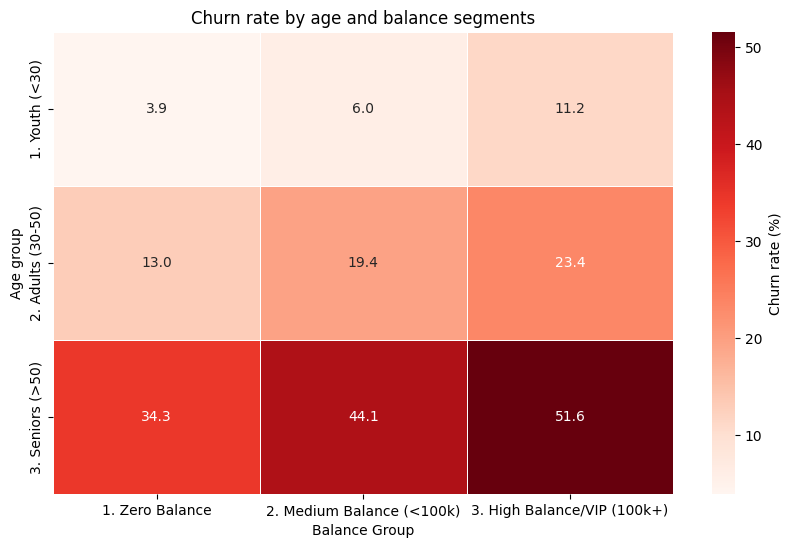

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Let's convert the churn metrics into a numerical format for building a summary table
segment_pivot = df.groupby(['AgeGroup', 'BalanceGroup'])['Exited'].mean().unstack() * 100

# Let's build a heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(segment_pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={'label': 'Churn rate (%)'}, linewidths=0.5)
plt.title('Churn rate by age and balance segments')
plt.xlabel('Balance Group')
plt.ylabel('Age group')
plt.show()

In [13]:
# Let's also look at the absolute volumes of lost funds in each segment
loss_segment = df[df['Exited'] == 1].groupby(['AgeGroup', 'BalanceGroup']).agg(
    lost_clients=('Exited', 'count'),
    total_lost_balance=('Balance', 'sum')
).reset_index()

loss_segment['total_lost_balance'] = loss_segment['total_lost_balance'].map('{:,.2f} €'.format)
display(loss_segment)

,AgeGroup,BalanceGroup,lost_clients,total_lost_balance
0,1. Youth (<30),1. Zero Balance,25,0.00 €
1,1. Youth (<30),2. Medium Balance (<100k),15,"1,114,663.90 €"
2,1. Youth (<30),3. High Balance/VIP (100k+),84,"11,333,809.23 €"
3,2. Adults (30-50),1. Zero Balance,333,0.00 €
4,2. Adults (30-50),2. Medium Balance (<100k),218,"17,435,971.49 €"
5,2. Adults (30-50),3. High Balance/VIP (100k+),799,"105,084,314.22 €"
6,3. Seniors (>50),1. Zero Balance,142,0.00 €
7,3. Seniors (>50),2. Medium Balance (<100k),93,"7,547,768.24 €"
8,3. Seniors (>50),3. High Balance/VIP (100k+),328,"43,071,567.55 €"
